<a href="https://colab.research.google.com/github/kky-zs/100-days-ml/blob/main/notebooks/phase-1-ml-core/day-004-gradient-boosting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 4: Gradient boosting (XGBoost, LightGBM, CatBoost) + Optuna

## Part 1

In [1]:
!pip install -q catboost optuna

In [2]:
import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import roc_auc_score, average_precision_score, accuracy_score, log_loss

import xgboost as xgb
import lightgbm as lgb
import catboost as cb
import optuna

RANDOM_STATE = 42
print("xgboost", xgb.__version__, "| lightgbm", lgb.__version__, "| catboost", cb.__version__, "| optuna", optuna.__version__)

xgboost 3.4.1 | lightgbm 4.6.0 | catboost 1.2.10 | optuna 5.1.0


## Part 2: Data and splits

In [3]:
adult = fetch_openml("adult", version=2, as_frame=True)
X, y = adult.data, (adult.target == ">50K").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=RANDOM_STATE
)
print(X_train.shape, X_tr.shape, X_val.shape, X_test.shape)

cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()
num_cols = X_train.select_dtypes(include="number").columns.tolist()
print("categorical:", cat_cols)

(39073, 14) (31258, 14) (7815, 14) (9769, 14)
categorical: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "accuracy": "accuracy"}

def cv_report(estimator, X, y, name):
    res = cross_validate(estimator, X, y, cv=cv, scoring=scoring, return_train_score=True)
    row = {"model": name}
    for k in scoring:
        row[f"{k} (cv)"] = f"{res['test_' + k].mean():.3f} ± {res['test_' + k].std():.3f}"
        row[f"{k} (train)"] = f"{res['train_' + k].mean():.3f}"
    row["fit time (s)"] = round(res["fit_time"].mean(), 1)
    return row

## Part 3: How gradient boosting works

Build the model as a sum of small trees, each one correcting the mistakes of the ensemble so far.

F(x) = F0 + η · (tree_1(x) + tree_2(x) + ... + tree_M(x))

For binary classification, F(x) is the log-odds and the probability is p = sigmoid(F). Each round:

- Compute the current probabilities p = sigmoid(F).
- Compute pseudo-residuals y − p. This is the negative gradient of the logloss with respect to F, which is why it’s “gradient” boosting: we do gradient descent in function space.
- Fit a small tree (depth 3-6) to those residuals.
- Set each leaf’s value with a Newton step: Σ(y − p) / Σ p(1−p).
- Add the tree to the ensemble, scaled by the learning rate η.

**XGBoost**: uses first and second derivatives (gradient g = p − y, Hessian h = p(1−p)). The optimal leaf weight is w = −G/(H + λ), and a split’s gain includes the L2 term λ and a per-leaf penalty γ, so regularization is built into the objective. It grows trees level-wise and has native handling of missing values and categoricals.

**LightGBM**: bins features into histograms (fast), and grows trees leaf-wise (always splits the leaf with the biggest gain), giving deeper, asymmetric trees that fit faster but can overfit small data. Control it with num_leaves and min_child_samples. It handles categoricals natively.

**CatBoost**: ordered boosting and ordered target statistics for categorical features, which avoid the target leakage that naive target encoding causes. It builds symmetric (oblivious) trees, which are fast to predict with, and has strong defaults, so it often works well untuned.

## Part 4: Build gradient boosting

In [5]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def logloss_from_F(y, F):
    p = np.clip(sigmoid(F), 1e-12, 1 - 1e-12)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))


class SimpleGBClassifier:
    def __init__(self, n_estimators=200, learning_rate=0.1, max_depth=3,
                 min_samples_leaf=20, subsample=1.0, random_state=0):
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.subsample = subsample
        self.random_state = random_state

    def fit(self, X, y, X_val=None, y_val=None):
        X, y = np.asarray(X), np.asarray(y, dtype=float)
        rng = np.random.default_rng(self.random_state)

        p0 = y.mean()
        # the model starts as the “always predict the base rate” baseline
        self.f0_ = np.log(p0 / (1 - p0))                 # start from the base-rate log-odds, (the log of the class ratio)
        F = np.full(len(y), self.f0_)
        F_val = None if X_val is None else np.full(len(X_val), self.f0_)

        self.trees_, self.leaf_values_ = [], []
        self.history_ = {"train_loss": [], "val_loss": []}

        for m in range(self.n_estimators):
            p = sigmoid(F)
            residual = y - p                              # negative gradient of logloss
            hess = p * (1 - p)

            # subsample < 1 trains each tree on a random fraction of rows (stochastic gradient boosting).
            idx = (rng.random(len(y)) < self.subsample) if self.subsample < 1.0 \
                  else np.ones(len(y), dtype=bool)

            tree = DecisionTreeRegressor(max_depth=self.max_depth,
                                         min_samples_leaf=self.min_samples_leaf,
                                         random_state=self.random_state + m)
            tree.fit(X[idx], residual[idx])

            # We replace the tree’s own leaf values with the Newton-step values, stored in a lookup array indexed by leaf id.
            leaf_ids = tree.apply(X) # returns the leaf each row falls into
            values = np.zeros(tree.tree_.node_count)
            for leaf in np.unique(leaf_ids[idx]):          # Newton step per leaf
                in_leaf = idx & (leaf_ids == leaf)
                values[leaf] = residual[in_leaf].sum() / (hess[in_leaf].sum() + 1e-12)

            F += self.learning_rate * values[leaf_ids]
            self.trees_.append(tree)
            self.leaf_values_.append(values)

            self.history_["train_loss"].append(logloss_from_F(y, F))
            if X_val is not None:
                F_val += self.learning_rate * values[tree.apply(np.asarray(X_val))]
                self.history_["val_loss"].append(logloss_from_F(np.asarray(y_val, dtype=float), F_val))
        return self

    def decision_function(self, X, n_trees=None):
        X = np.asarray(X)
        F = np.full(len(X), self.f0_)
        for tree, values in list(zip(self.trees_, self.leaf_values_))[:n_trees]:
            F += self.learning_rate * values[tree.apply(X)]
        return F

    def predict_proba(self, X, n_trees=None):
        p = sigmoid(self.decision_function(X, n_trees))
        return np.column_stack([1 - p, p])

fit time: 186s
val ROC AUC: 0.9285
val logloss is lowest at round 661


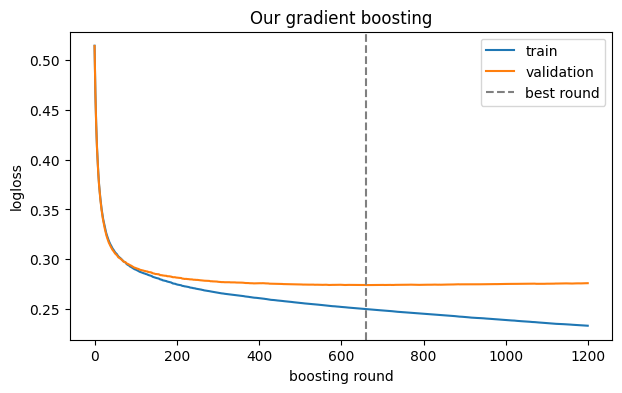

In [6]:
# Run it. Our simple trees need numeric input, so we one-hot encode (fitted on the training part only,
# to stay leak-proof) and fit the encoder inside this cell.

prep = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), make_column_selector(dtype_include=np.number)),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="missing")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), make_column_selector(dtype_exclude=np.number)),
])
A_tr = prep.fit_transform(X_tr)          # fit on the training part only
A_val = prep.transform(X_val)

t0 = time.time()
my_gb = SimpleGBClassifier(n_estimators=1200, learning_rate=0.1, max_depth=3).fit(A_tr, y_tr, A_val, y_val)
print(f"fit time: {time.time() - t0:.0f}s")

hist = my_gb.history_
best_round = int(np.argmin(hist["val_loss"])) + 1
print("val ROC AUC:", round(roc_auc_score(y_val, my_gb.predict_proba(A_val)[:, 1]), 4))
print("val logloss is lowest at round", best_round)

plt.figure(figsize=(7, 4))
plt.plot(hist["train_loss"], label="train")
plt.plot(hist["val_loss"], label="validation")
plt.axvline(best_round - 1, color="gray", linestyle="--", label="best round")
plt.xlabel("boosting round"); plt.ylabel("logloss"); plt.legend(); plt.title("Our gradient boosting")
plt.show()

## Part 5: The three libraries, and how each handles categoricals

Unlike linear models, tree libraries don’t need one-hot encoding, and giving them categoricals natively is usually better (it avoids exploding the feature space). There’s also no scaling or imputation step to leak, since all three handle missing values natively.

**XGBoost**: pandas category dtype plus enable_categorical=True (with tree_method="hist").

**LightGBM**: picks up pandas category columns automatically.

**CatBoost**: wants the categorical columns listed in cat_features and as strings, with no NaN, so we convert them to text with “missing” as its own value.

In [7]:
def to_catboost_frame(df):
    out = df.copy()
    for c in cat_cols:
        out[c] = out[c].astype(object).fillna("missing").astype(str)
    return out

X_train_cb, X_test_cb = to_catboost_frame(X_train), to_catboost_frame(X_test)
X_tr_cb, X_val_cb = to_catboost_frame(X_tr), to_catboost_frame(X_val)

## Part 6: Defaults head to head (cross-validation)

Compare the three libraries with the same budget (300 trees, learning rate 0.1) on the same folds.

In [8]:
rows = []
rows.append(cv_report(
    xgb.XGBClassifier(n_estimators=300, learning_rate=0.1, tree_method="hist",
                      enable_categorical=True, random_state=RANDOM_STATE),
    X_train, y_train, "XGBoost (defaults)"))
rows.append(cv_report(
    lgb.LGBMClassifier(n_estimators=300, learning_rate=0.1, random_state=RANDOM_STATE, verbose=-1),
    X_train, y_train, "LightGBM (defaults)"))
rows.append(cv_report(
    cb.CatBoostClassifier(
        iterations=300,
        learning_rate=0.1,
        random_seed=RANDOM_STATE,
        cat_features=tuple(cat_cols),
        verbose=False
    ),
    X_train_cb, y_train, "CatBoost (defaults)"
))

results = pd.DataFrame(rows).set_index("model")
results

,roc_auc (cv),roc_auc (train),pr_auc (cv),pr_auc (train),accuracy (cv),accuracy (train),fit time (s)
model,,,,,,,
XGBoost (defaults),0.927 ± 0.002,0.966,0.825 ± 0.006,0.909,0.870 ± 0.004,0.910,2.6
LightGBM (defaults),0.927 ± 0.003,0.970,0.825 ± 0.008,0.918,0.870 ± 0.006,0.913,1.1
CatBoost (defaults),0.929 ± 0.003,0.940,0.829 ± 0.008,0.854,0.873 ± 0.004,0.884,18.2


## Part 7: Early stopping and learning curves

Instead of guessing the number of trees, set a large maximum and stop when the validation score hasn’t improved for N rounds (here 50). We train each library on X_tr, watch X_val, and plot logloss curves.

best number of trees: {'XGBoost': 295, 'LightGBM': 206, 'CatBoost': 812}


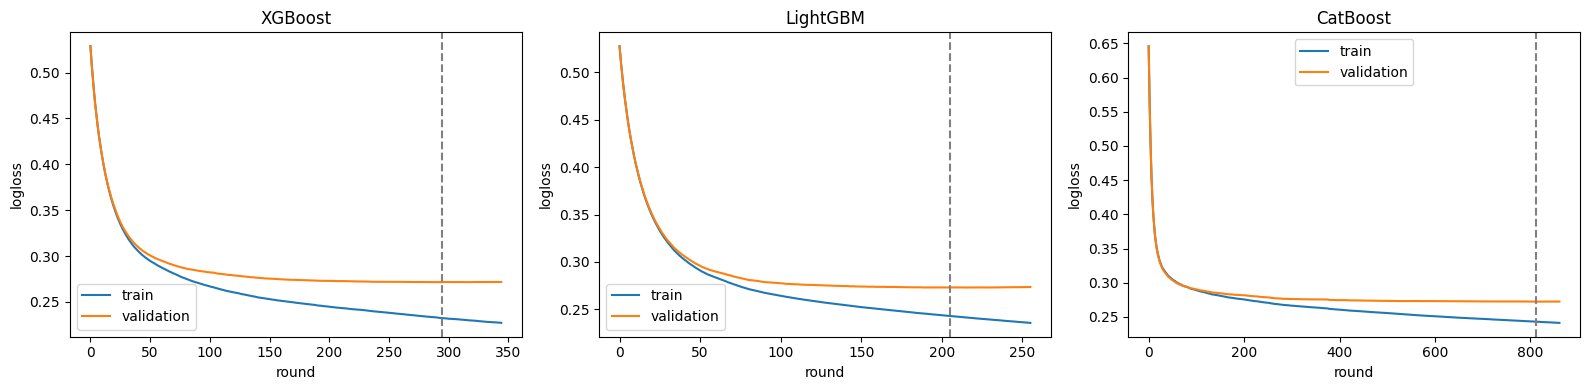

In [9]:
# XGBoost
xgb_es = xgb.XGBClassifier(n_estimators=2000, learning_rate=0.05, tree_method="hist",
                           enable_categorical=True, eval_metric="logloss",
                           early_stopping_rounds=50, random_state=RANDOM_STATE)
xgb_es.fit(X_tr, y_tr, eval_set=[(X_tr, y_tr), (X_val, y_val)], verbose=False)
xgb_ev = xgb_es.evals_result()
xgb_curves = (xgb_ev["validation_0"]["logloss"], xgb_ev["validation_1"]["logloss"])

# LightGBM
lgb_es = lgb.LGBMClassifier(n_estimators=2000, learning_rate=0.05, random_state=RANDOM_STATE, verbose=-1)
lgb_es.fit(X_tr, y_tr, eval_set=[(X_tr, y_tr), (X_val, y_val)], eval_names=["train", "val"],
           eval_metric="binary_logloss", callbacks=[lgb.early_stopping(50, verbose=False)])
lgb_ev = lgb_es.evals_result_
lgb_curves = (lgb_ev["train"]["binary_logloss"], lgb_ev["val"]["binary_logloss"])

# CatBoost
cb_es = cb.CatBoostClassifier(iterations=2000, learning_rate=0.05, eval_metric="Logloss",
                              early_stopping_rounds=50, cat_features=cat_cols,
                              random_seed=RANDOM_STATE, verbose=False)
cb_es.fit(X_tr_cb, y_tr, eval_set=(X_val_cb, y_val))
cb_ev = cb_es.get_evals_result()
cb_curves = (cb_ev["learn"]["Logloss"], cb_ev["validation"]["Logloss"])

best_iters = {"XGBoost": xgb_es.best_iteration + 1,
              "LightGBM": lgb_es.best_iteration_,
              "CatBoost": cb_es.get_best_iteration() + 1}
print("best number of trees:", best_iters)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, (tr_c, va_c)) in zip(axes, {"XGBoost": xgb_curves, "LightGBM": lgb_curves, "CatBoost": cb_curves}.items()):
    ax.plot(tr_c, label="train"); ax.plot(va_c, label="validation")
    ax.axvline(best_iters[name] - 1, color="gray", linestyle="--")
    ax.set_title(name); ax.set_xlabel("round"); ax.set_ylabel("logloss"); ax.legend()
plt.tight_layout(); plt.show()

## Part 8: The hyperparameters that matter

Where each knob pushes you:

- **learning_rate**: smaller means smoother and better, but needs more trees. Typical: 0.01-0.1 with early stopping.

- **Number of trees**: don’t tune it directly; set it high and use early stopping.

- **Tree complexity**: XGBoost/CatBoost max_depth / depth (3-10), LightGBM num_leaves (keep it well below 2^max_depth).

- **Minimum leaf size**: XGBoost min_child_weight, LightGBM min_child_samples, CatBoost min_data_in_leaf.

- **Row subsampling (subsample) and column subsampling (colsample_bytree)**: values of 0.5-0.9 add randomness and reduce overfitting.

- **L2/L1 regularization**: reg_lambda, reg_alpha (CatBoost l2_leaf_reg). Bigger means shrinkage on leaf weights.

Grid search over this many knobs is hopeless, which is what Optuna is for.

## Part 9: Tuning with Optuna

Optuna builds a model of which regions of the search space score well (the default sampler is TPE) and samples more from promising regions. It also supports pruning: abandoning a trial early when its first folds look clearly worse than the median.

In [10]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
fixed = dict(subsample_freq=1, random_state=RANDOM_STATE, verbose=-1)

def objective(trial):
    params = dict(
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        num_leaves=trial.suggest_int("num_leaves", 8, 128, log=True),
        min_child_samples=trial.suggest_int("min_child_samples", 10, 200, log=True),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
        reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
    )
    scores, best_iters = [], []
    for fold, (tr_idx, va_idx) in enumerate(cv3.split(X_train, y_train)):
        X_a, X_b = X_train.iloc[tr_idx], X_train.iloc[va_idx]
        y_a, y_b = y_train.iloc[tr_idx], y_train.iloc[va_idx]
        model = lgb.LGBMClassifier(**fixed, **params, n_estimators=2000)
        model.fit(X_a, y_a, eval_set=[(X_b, y_b)], eval_metric="auc",
                  callbacks=[lgb.early_stopping(50, verbose=False)])
        scores.append(roc_auc_score(y_b, model.predict_proba(X_b)[:, 1]))
        best_iters.append(model.best_iteration_)

        trial.report(float(np.mean(scores)), step=fold)
        if trial.should_prune():
            raise optuna.TrialPruned()

    trial.set_user_attr("best_iter", int(np.mean(best_iters)))
    return float(np.mean(scores))

study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=1),
)
study.optimize(objective, n_trials=30, show_progress_bar=True)   # a few minutes

print("best CV ROC AUC:", round(study.best_value, 4))
print("best params:", study.best_params)
print("mean best iteration:", study.best_trial.user_attrs["best_iter"])

  0%|          | 0/30 [00:00<?, ?it/s]

best CV ROC AUC: 0.929
best params: {'learning_rate': 0.03812371157664857, 'num_leaves': 33, 'min_child_samples': 21, 'subsample': 0.952196938501596, 'colsample_bytree': 0.42235722078982074, 'reg_lambda': 0.015254673865332986, 'reg_alpha': 0.048920816716211006}
mean best iteration: 325


In [11]:
n_pruned = sum(t.state == optuna.trial.TrialState.PRUNED for t in study.trials)
print(f"{len(study.trials)} trials, {n_pruned} pruned")

optuna.visualization.plot_optimization_history(study).show()
optuna.visualization.plot_param_importances(study).show()

30 trials, 2 pruned


In [12]:
# tune XGBoost the same way

def objective_xgb(trial):
    params = dict(
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        max_depth=trial.suggest_int("max_depth", 3, 10),
        min_child_weight=trial.suggest_float("min_child_weight", 1.0, 50.0, log=True),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
        reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
    )
    scores, best_iters = [], []
    for fold, (tr_idx, va_idx) in enumerate(cv3.split(X_train, y_train)):
        X_a, X_b = X_train.iloc[tr_idx], X_train.iloc[va_idx]
        y_a, y_b = y_train.iloc[tr_idx], y_train.iloc[va_idx]
        model = xgb.XGBClassifier(**params, n_estimators=2000, tree_method="hist",
                                  enable_categorical=True, eval_metric="auc",
                                  early_stopping_rounds=50, random_state=RANDOM_STATE)
        model.fit(X_a, y_a, eval_set=[(X_b, y_b)], verbose=False)
        scores.append(roc_auc_score(y_b, model.predict_proba(X_b)[:, 1]))
        best_iters.append(model.best_iteration + 1)
        trial.report(float(np.mean(scores)), step=fold)
        if trial.should_prune():
            raise optuna.TrialPruned()
    trial.set_user_attr("best_iter", int(np.mean(best_iters)))
    return float(np.mean(scores))

study_xgb = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=1),
)

study_xgb.optimize(objective_xgb, n_trials=30, show_progress_bar=True)

print("best CV ROC AUC:", round(study_xgb.best_value, 4))
print("best params:", study_xgb.best_params)
print("mean best iteration:", study_xgb.best_trial.user_attrs["best_iter"])
print("best CV ROC AUC:", round(study.best_value, 4))
print("best params:", study.best_params)
print("mean best iteration:", study.best_trial.user_attrs["best_iter"])

  0%|          | 0/30 [00:00<?, ?it/s]

best CV ROC AUC: 0.9285
best params: {'learning_rate': 0.054084957210019116, 'max_depth': 6, 'min_child_weight': 1.4477073690038331, 'subsample': 0.9733823151875263, 'colsample_bytree': 0.5887324136642575, 'reg_lambda': 1.0813541034825334, 'reg_alpha': 0.6126549388868332}
mean best iteration: 274
best CV ROC AUC: 0.929
best params: {'learning_rate': 0.03812371157664857, 'num_leaves': 33, 'min_child_samples': 21, 'subsample': 0.952196938501596, 'colsample_bytree': 0.42235722078982074, 'reg_lambda': 0.015254673865332986, 'reg_alpha': 0.048920816716211006}
mean best iteration: 325


In [16]:
n_pruned = sum(t.state == optuna.trial.TrialState.PRUNED for t in study_xgb.trials)
print(f"{len(study_xgb.trials)} trials, {n_pruned} pruned")

optuna.visualization.plot_optimization_history(study_xgb).show()
optuna.visualization.plot_param_importances(study_xgb).show()

30 trials, 3 pruned


## Part 10: The final test

Refit the tuned LightGBM on the whole training set and evaluate on the test set once. The trees were chosen with about two-thirds of the data per fold, so we use about 10% more trees for the full training set.

In [17]:
n_trees = int(study.best_trial.user_attrs["best_iter"] * 1.1)
final_params = {**fixed, **study.best_params, "n_estimators": n_trees, "importance_type": "gain"}

final_lgb = lgb.LGBMClassifier(**final_params)
final_lgb.fit(X_train, y_train)

proba = final_lgb.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

print(f"trees used          : {n_trees}")
print(f"TEST ROC AUC        : {roc_auc_score(y_test, proba):.4f}")
print(f"TEST PR AUC         : {average_precision_score(y_test, proba):.4f}   (random baseline = {y_test.mean():.3f})")
print(f"TEST log loss       : {log_loss(y_test, proba):.4f}")
print(f"TEST accuracy       : {accuracy_score(y_test, pred):.4f}")
print(f"CV ROC AUC (tuning) : {study.best_value:.4f}")

trees used          : 357
TEST ROC AUC        : 0.9312
TEST PR AUC         : 0.8360   (random baseline = 0.239)
TEST log loss       : 0.2711
TEST accuracy       : 0.8779
CV ROC AUC (tuning) : 0.9290


## Part 11: What did the model learn?

We use gain-based importance (how much each feature improved the loss across all its splits). Caveats: importance is not causation, it is split between correlated features, and impurity or gain-based measures favor high-cardinality features.

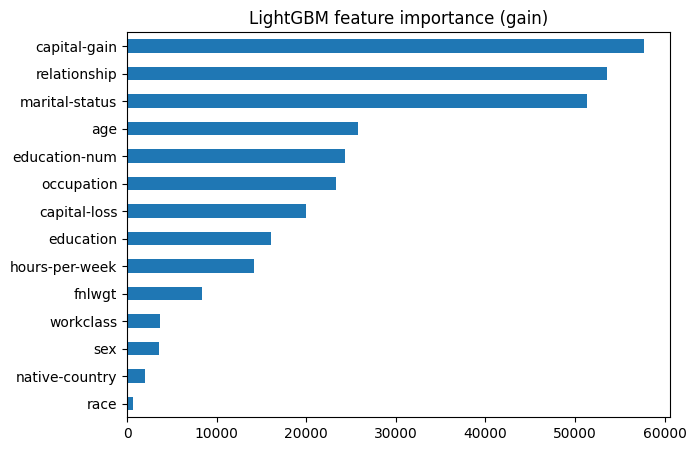

In [18]:
imp = pd.Series(final_lgb.feature_importances_, index=X_train.columns).sort_values(ascending=False)
imp.head(15).iloc[::-1].plot.barh(figsize=(7, 5), title="LightGBM feature importance (gain)")
plt.show()